# Bank Customer Churn Prediction — Three-Dataset Study

**Project type:** Binary classification  
**Models:** Logistic Regression (baseline) and Random Forest  
**Datasets (analysed separately, never merged):**

| Key | Dataset | File | Target |
|---|---|---|---|
| D1 | Churn Modelling (Kaggle, shrutimechlearn) | `Churn_Modelling.csv` | `Exited` |
| D2 | Bank Customer Churn, Playground Series S4E1 (Kaggle) | `train.csv` | `Exited` |
| D3 | Credit Card Customers / BankChurners (Kaggle, sakshigoyal7) | `BankChurners.csv` | `Attrition_Flag` → 1 = attrited |

**Research question:** Can customer account, demographic and financial attributes predict whether a bank customer leaves, and do the findings hold across different bank-customer datasets?

**Origin of the code:** the pipeline (split, preprocessing, models, metrics, 0.35 threshold experiment) is the one from the original `ARPAN_Bank_Customer_Churn_Prediction.ipynb`, unchanged, wrapped in a function so it can run on each dataset. Dataset 1 should therefore reproduce your original results exactly.

**Why separate datasets, not one merged table?** The three files have different columns, different customer populations and different churn rates. Merging them would be meaningless. Instead we run the same method on each and compare the results.

**Roadmap:** 1 Imports → 2 Dataset configuration → 3 Loading helper → 4 Pipeline function → 5–7 Run D1, D2, D3 → 8 Cross-dataset comparison → 9 Optional model saving → 10 Discussion.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

RANDOM_STATE = 42
THRESHOLD = 0.35          # same experimental threshold as the original notebook
SAVE_MODELS = True      # set True in Section 9 only if you want .joblib files
print("Libraries imported.")

Libraries imported.


## 2. Dataset configuration

One dictionary describes everything that differs between datasets. **Nothing else in the notebook is dataset-specific.**

- `file`: the CSV filename expected in the Colab session.
- `target`: the target column. `target_map` converts text labels to 0/1 when needed (D3).
- `drop`: identifier columns, and (D3) two leaked/unrelated columns, that must not be used as inputs.
- `eda_cols`: three columns used for the churn-rate bar plots.

**D3 note:** `BankChurners.csv` ends with two columns whose names begin `Naive_Bayes_Classifier_...`. The dataset's author states they should be removed; they are the output of another classifier and would leak information about the target. They are dropped here.

In [ ]:
DATASETS = {
    "D1": {
        "name": "Churn Modelling",
        "file": "Churn_Modelling.csv",
        "target": "Exited",
        "target_map": None,
        "drop": ["RowNumber", "CustomerId", "Surname"],
        "eda_cols": ["Geography", "Gender", "IsActiveMember"],
    },
    "D2": {
        "name": "Playground S4E1",
        "file": "train.csv",
        "target": "Exited",
        "target_map": None,
        "drop": ["id", "CustomerId", "Surname"],
        "eda_cols": ["Geography", "Gender", "IsActiveMember"],
    },
    "D3": {
        "name": "BankChurners",
        "file": "BankChurners.csv",
        "target": "Attrition_Flag",
        "target_map": {"Existing Customer": 0, "Attrited Customer": 1},
        "drop": ["CLIENTNUM"],          # plus the Naive_Bayes columns, removed by prefix below
        "drop_prefix": "Naive_Bayes_Classifier",
        "eda_cols": ["Gender", "Card_Category", "Marital_Status"],
    },
}
for k, v in DATASETS.items():
    print(k, "->", v["file"], "| target:", v["target"])

D1 -> Churn_Modelling.csv | target: Exited
D2 -> train.csv | target: Exited
D3 -> BankChurners.csv | target: Attrition_Flag


## 3. Loading helper

`ensure_files()` checks which CSV files are missing. If any are, it opens **one** Colab upload dialog; select all missing files together. Files already in the session are not asked for again.

In [ ]:
def ensure_files(keys):
    missing = [DATASETS[k]["file"] for k in keys if not Path(DATASETS[k]["file"]).exists()]
    if not missing:
        print("All requested files already present.")
        return
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(f"Place these files next to the notebook: {missing}") from exc
    print("Please upload:", missing)
    files.upload()
    still = [f for f in missing if not Path(f).exists()]
    if still:
        raise FileNotFoundError(
            f"Still missing: {still}. Check the filename spelling exactly "
            "(Colab renames duplicates like 'train (1).csv')."
        )


def load_dataset(key):
    cfg = DATASETS[key]
    df = pd.read_csv(cfg["file"])
    print(f"[{key}] {cfg['name']}: {df.shape[0]:,} rows x {df.shape[1]} columns")

    if cfg["target"] not in df.columns:
        raise ValueError(f"[{key}] target column '{cfg['target']}' not found. Columns: {list(df.columns)}")

    drop_cols = [c for c in cfg["drop"] if c in df.columns]
    prefix = cfg.get("drop_prefix")
    if prefix:
        drop_cols += [c for c in df.columns if c.startswith(prefix)]
    data = df.drop(columns=drop_cols).copy()

    y = data[cfg["target"]]
    if cfg["target_map"]:
        unknown = set(y.dropna().unique()) - set(cfg["target_map"])
        if unknown:
            raise ValueError(f"[{key}] unexpected target labels: {unknown}")
        y = y.map(cfg["target_map"])
    if y.isna().any():
        raise ValueError(f"[{key}] target contains missing values.")
    y = y.astype(int)
    X = data.drop(columns=[cfg["target"]])
    return df, X, y, drop_cols

## 4. The reusable pipeline

`run_pipeline(key)` performs the original notebook's workflow in order:

1. load and inspect (shape, missing values, duplicates, churn rate, churn plots)
2. stratified 80/20 split (`random_state=42`)
3. preprocessing inside `Pipeline`/`ColumnTransformer` (fit on training data only → no leakage)
4. Logistic Regression and Random Forest (`class_weight="balanced"`)
5. accuracy, churn-class precision/recall/F1, confusion matrices, ROC-AUC
6. Random Forest feature importance
7. threshold experiment, 0.50 vs 0.35

It returns a results table (and the fitted Random Forest) for the final comparison.

In [ ]:
def metric_row(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Churn precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Churn recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Churn F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


def run_pipeline(key):
    cfg = DATASETS[key]
    ensure_files([key])
    df, X, y, dropped = load_dataset(key)

    # ---- inspection ----
    print("Dropped columns:", dropped)
    print("Missing values (total):", int(df.isnull().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))
    display(df.head())
    counts = y.value_counts().reindex([0, 1], fill_value=0)
    churn_rate = y.mean() * 100
    print(f"Stayed: {counts[0]:,} | Left: {counts[1]:,} | Churn rate: {churn_rate:.2f}%")

    # ---- EDA plots ----
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    counts.rename(index={0: "Stayed (0)", 1: "Left (1)"}).plot(kind="bar", ax=axes[0], rot=0)
    axes[0].set_title(f"{key}: Churn distribution"); axes[0].set_ylabel("Customers")
    tmp = X.copy(); tmp["_y"] = y
    for ax, col in zip(axes[1:], cfg["eda_cols"]):
        if col in tmp.columns:
            (tmp.groupby(col, observed=False)["_y"].mean().sort_values(ascending=False) * 100).plot(kind="bar", ax=ax, rot=20)
            ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate (%)")
    plt.tight_layout(); plt.show()

    # ---- split ----
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    print("Train:", X_train.shape, "| Test:", X_test.shape)

    # ---- preprocessing (identical to original notebook) ----
    numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()
    print("Numeric features:", numeric_features)
    print("Categorical features:", categorical_features)

    num_lr = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    num_rf = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))])
    pre_lr = ColumnTransformer([("numeric", num_lr, numeric_features), ("categorical", cat, categorical_features)])
    pre_rf = ColumnTransformer([("numeric", num_rf, numeric_features), ("categorical", cat, categorical_features)])

    # ---- models (identical to original notebook) ----
    logistic_model = Pipeline([("preprocessor", pre_lr),
                               ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    random_forest_model = Pipeline([("preprocessor", pre_rf),
                                    ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE,
                                                                          class_weight="balanced", n_jobs=-1))])
    logistic_model.fit(X_train, y_train)
    lr_pred = logistic_model.predict(X_test)
    lr_prob = logistic_model.predict_proba(X_test)[:, 1]
    print("Logistic Regression trained.")
    random_forest_model.fit(X_train, y_train)
    rf_pred = random_forest_model.predict(X_test)
    rf_prob = random_forest_model.predict_proba(X_test)[:, 1]
    print("Random Forest trained.")
    rf_pred_t = (rf_prob >= THRESHOLD).astype(int)

    # ---- detailed reports ----
    labels = ["Stayed (0)", "Left (1)"]
    for title, pred in [("Logistic Regression (0.50)", lr_pred),
                        ("Random Forest (0.50)", rf_pred),
                        (f"Random Forest ({THRESHOLD:.2f})", rf_pred_t)]:
        print(f"\n===== {key} | {title} =====")
        print(f"Accuracy: {accuracy_score(y_test, pred):.4f}")
        print(classification_report(y_test, pred, target_names=labels, zero_division=0))
        print("Confusion matrix [[TN, FP],[FN, TP]]:\n", confusion_matrix(y_test, pred))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (title, pred) in zip(axes, [("Logistic Regression (0.50)", lr_pred),
                                        ("Random Forest (0.50)", rf_pred),
                                        (f"Random Forest ({THRESHOLD:.2f})", rf_pred_t)]):
        ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Left"], cmap="Blues", ax=ax)
        ax.set_title(title)
    plt.suptitle(f"{key}: confusion matrices"); plt.tight_layout(); plt.show()

    # ---- ROC-AUC ----
    auc_lr = roc_auc_score(y_test, lr_prob)
    auc_rf = roc_auc_score(y_test, rf_prob)
    print(f"ROC-AUC  LR: {auc_lr:.4f} | RF: {auc_rf:.4f}")
    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression", ax=ax)
    RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest", ax=ax)
    ax.set_title(f"{key}: ROC curves"); plt.tight_layout(); plt.show()

    # ---- feature importance ----
    names = random_forest_model.named_steps["preprocessor"].get_feature_names_out()
    importance = pd.DataFrame({"Feature": names,
                               "Importance": random_forest_model.named_steps["classifier"].feature_importances_}
                              ).sort_values("Importance", ascending=False)
    top = importance.head(10).sort_values("Importance")
    plt.figure(figsize=(9, 5)); plt.barh(top["Feature"], top["Importance"])
    plt.title(f"{key}: Top 10 Random Forest features"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()

    # ---- consolidated table ----
    results = pd.DataFrame([
        {**metric_row("Logistic Regression (0.50)", y_test, lr_pred), "ROC-AUC": auc_lr},
        {**metric_row("Random Forest (0.50)", y_test, rf_pred), "ROC-AUC": auc_rf},
        {**metric_row(f"Random Forest ({THRESHOLD:.2f})", y_test, rf_pred_t), "ROC-AUC": auc_rf},
    ])
    results.insert(0, "Dataset", key)
    results["Churn rate %"] = round(churn_rate, 2)
    results["Rows"] = len(df)
    display(results.round(4))
    return {"results": results, "importance": importance, "rf_model": random_forest_model,
            "columns": list(X_train.columns)}

ALL = {}   # filled by the next sections

## 5. Run D1: Churn Modelling (original notebook dataset)

Expected file: `Churn_Modelling.csv`

Please upload: ['Churn_Modelling.csv']


Saving Churn_Modelling.csv to Churn_Modelling.csv
[D1] Churn Modelling: 10,000 rows x 14 columns
Dropped columns: ['RowNumber', 'CustomerId', 'Surname']
Missing values (total): 0
Duplicate rows: 0


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Stayed: 7,963 | Left: 2,037 | Churn rate: 20.37%


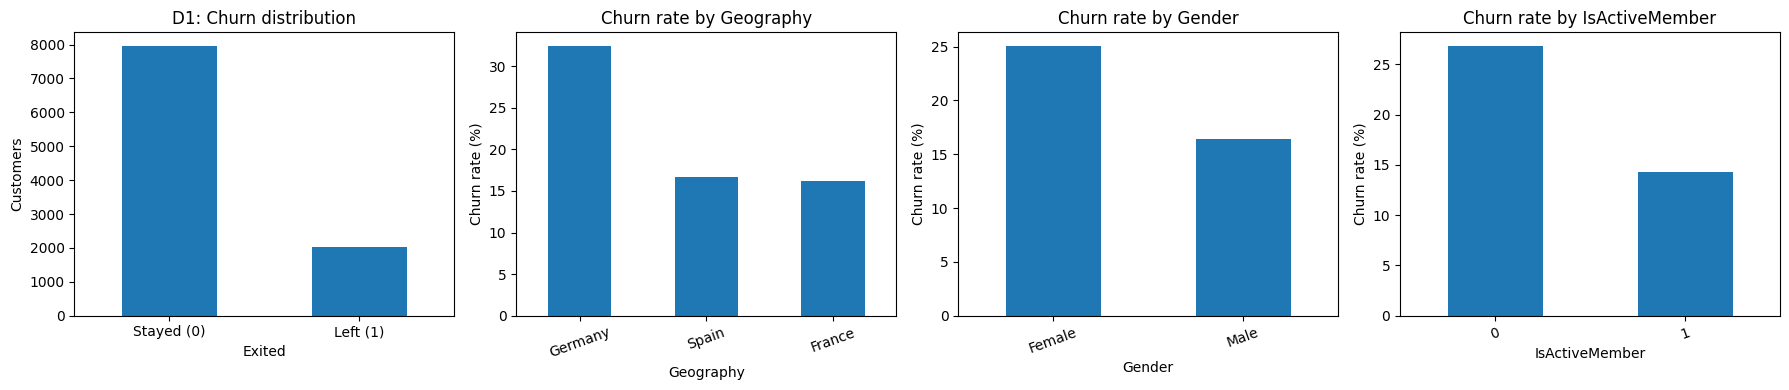

Train: (8000, 10) | Test: (2000, 10)
Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']
Logistic Regression trained.
Random Forest trained.

===== D1 | Logistic Regression (0.50) =====
Accuracy: 0.8080
              precision    recall  f1-score   support

  Stayed (0)       0.82      0.97      0.89      1593
    Left (1)       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000

Confusion matrix [[TN, FP],[FN, TP]]:
 [[1540   53]
 [ 331   76]]

===== D1 | Random Forest (0.50) =====
Accuracy: 0.8615
              precision    recall  f1-score   support

  Stayed (0)       0.87      0.97      0.92      1593
    Left (1)       0.79      0.44      0.56       407

    accuracy                           0.86      2000
   macr

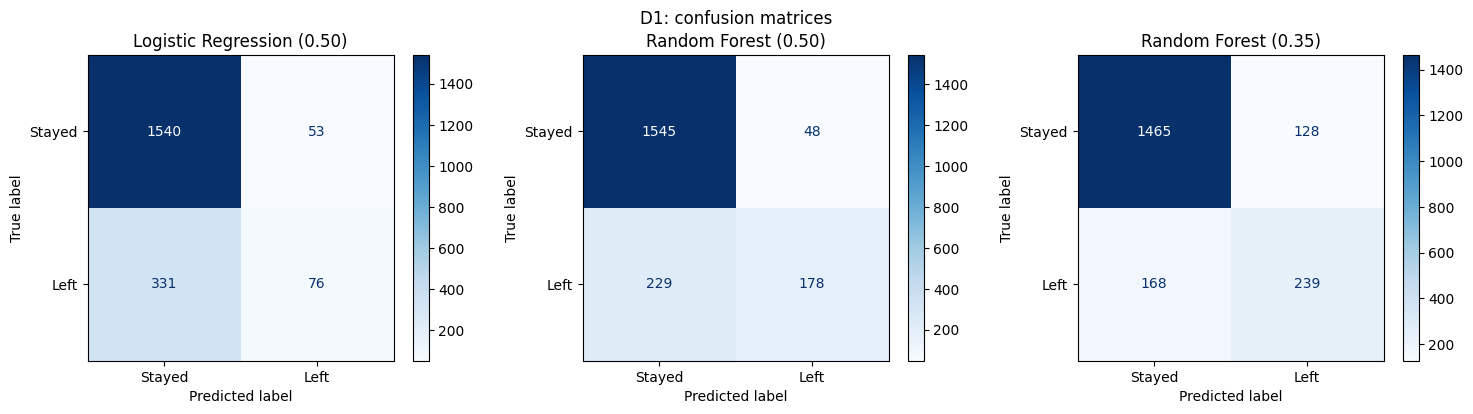

ROC-AUC  LR: 0.7748 | RF: 0.8553


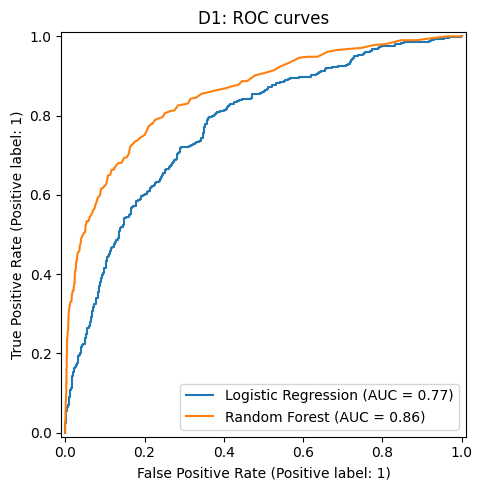

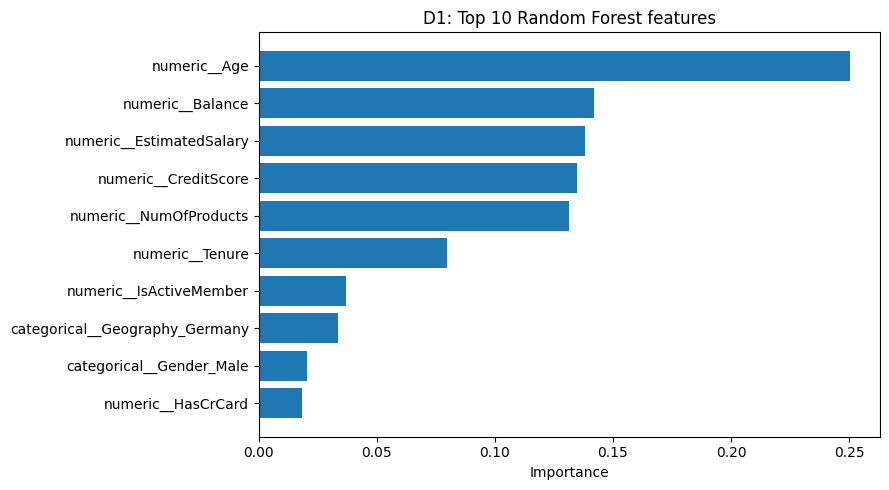

,Dataset,Model,Accuracy,Churn precision,Churn recall,Churn F1-score,ROC-AUC,Churn rate %,Rows
0,D1,Logistic Regression (0.50),0.8080,0.5891,0.1867,0.2836,0.7748,20.37,10000
1,D1,Random Forest (0.50),0.8615,0.7876,0.4373,0.5624,0.8553,20.37,10000
2,D1,Random Forest (0.35),0.8520,0.6512,0.5872,0.6176,0.8553,20.37,10000


In [ ]:
ALL["D1"] = run_pipeline("D1")

## 6. Run D2: Playground Series S4E1 (large, synthetic-style)

Expected file: `train.csv`

**Runtime note:** this file is far larger than D1, so Random Forest training can take a few minutes on Colab's CPU. That is normal.

Please upload: ['train.csv']


Saving train.csv to train.csv
[D2] Playground S4E1: 165,034 rows x 14 columns
Dropped columns: ['id', 'CustomerId', 'Surname']
Missing values (total): 0
Duplicate rows: 0


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


Stayed: 130,113 | Left: 34,921 | Churn rate: 21.16%


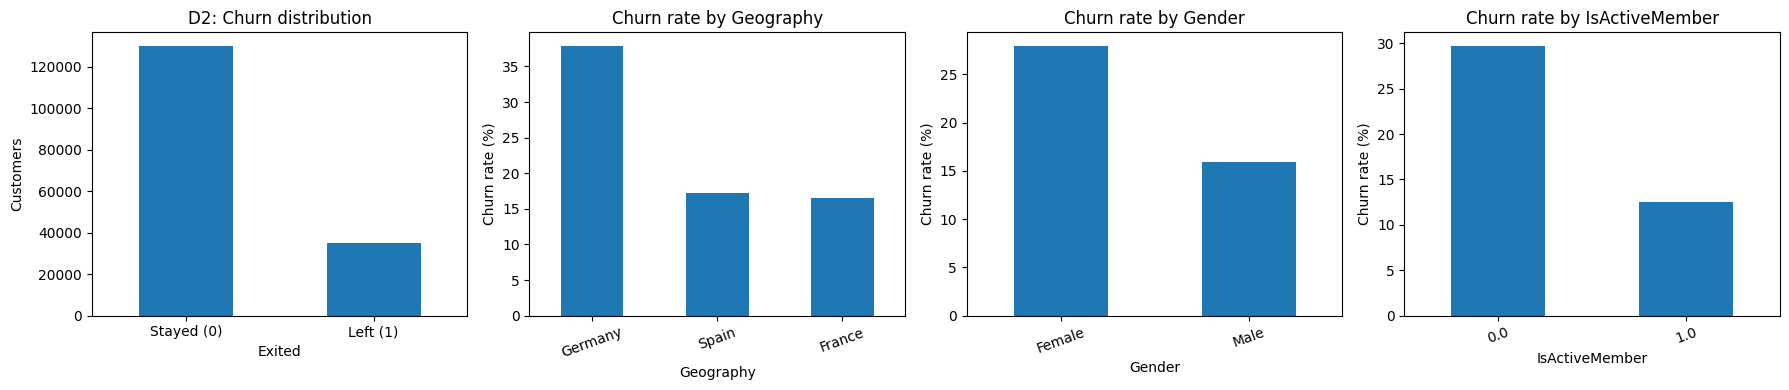

Train: (132027, 10) | Test: (33007, 10)
Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']
Logistic Regression trained.
Random Forest trained.

===== D2 | Logistic Regression (0.50) =====
Accuracy: 0.8335
              precision    recall  f1-score   support

  Stayed (0)       0.85      0.95      0.90     26023
    Left (1)       0.69      0.38      0.49      6984

    accuracy                           0.83     33007
   macro avg       0.77      0.67      0.70     33007
weighted avg       0.82      0.83      0.81     33007

Confusion matrix [[TN, FP],[FN, TP]]:
 [[24847  1176]
 [ 4321  2663]]

===== D2 | Random Forest (0.50) =====
Accuracy: 0.8596
              precision    recall  f1-score   support

  Stayed (0)       0.88      0.95      0.91     26023
    Left (1)       0.74      0.52      0.61      6984

    accuracy                           0.86     33007


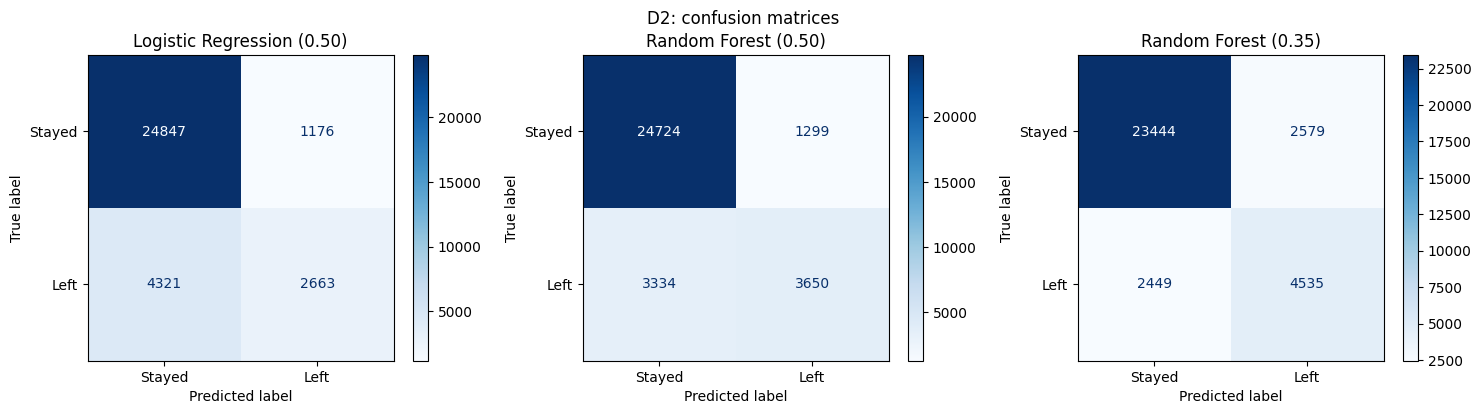

ROC-AUC  LR: 0.8145 | RF: 0.8739


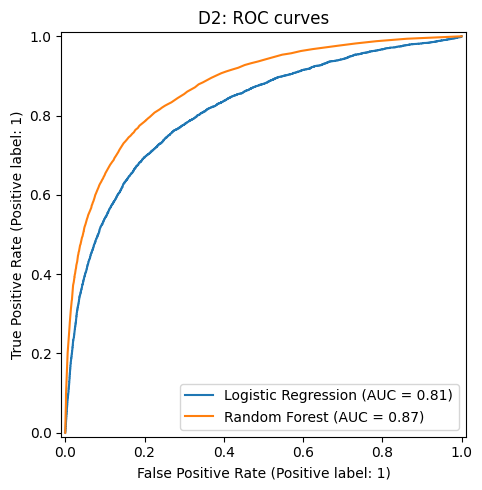

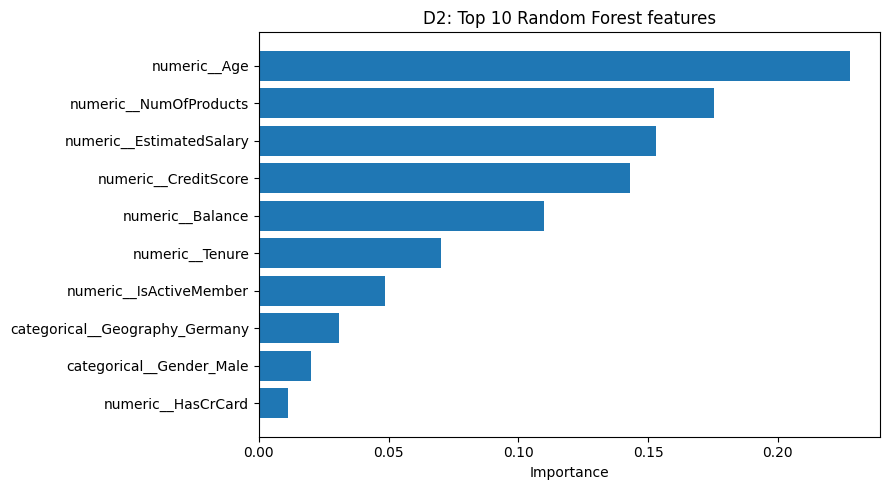

,Dataset,Model,Accuracy,Churn precision,Churn recall,Churn F1-score,ROC-AUC,Churn rate %,Rows
0,D2,Logistic Regression (0.50),0.8335,0.6937,0.3813,0.4921,0.8145,21.16,165034
1,D2,Random Forest (0.50),0.8596,0.7375,0.5226,0.6117,0.8739,21.16,165034
2,D2,Random Forest (0.35),0.8477,0.6375,0.6493,0.6434,0.8739,21.16,165034


In [ ]:
ALL["D2"] = run_pipeline("D2")

## 7. Run D3: BankChurners (credit-card customers)

Expected file: `BankChurners.csv`

**Different schema:** the features are credit-card behaviour columns (e.g. transaction counts and amounts, utilisation), not Geography/Balance. The same pipeline handles this automatically because column types are detected, not hard-coded.

Please upload: ['BankChurners.csv']


Saving BankChurners.csv to BankChurners.csv
[D3] BankChurners: 10,127 rows x 23 columns
Dropped columns: ['CLIENTNUM', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Missing values (total): 0
Duplicate rows: 0


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


Stayed: 8,500 | Left: 1,627 | Churn rate: 16.07%


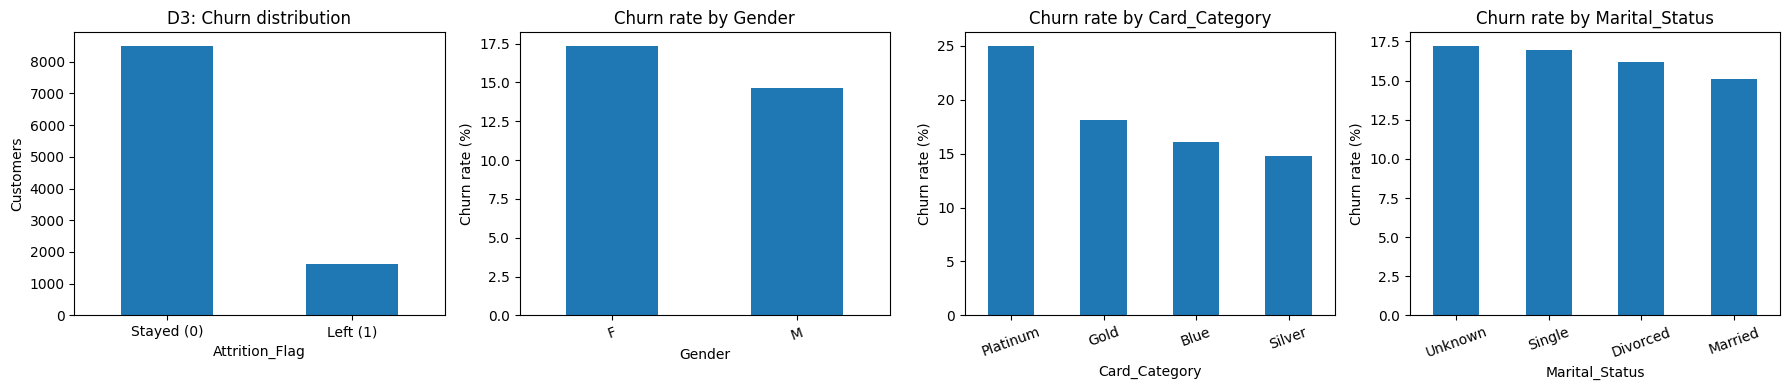

Train: (8101, 19) | Test: (2026, 19)
Numeric features: ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Categorical features: ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']
Logistic Regression trained.
Random Forest trained.

===== D3 | Logistic Regression (0.50) =====
Accuracy: 0.9008
              precision    recall  f1-score   support

  Stayed (0)       0.92      0.97      0.94      1701
    Left (1)       0.77      0.54      0.64       325

    accuracy                           0.90      2026
   macro avg       0.84      0.76      0.79      2026
weighted avg       0.89      0.90      0.89      2026

Confusion matrix [[TN, FP],[FN, TP]]:
 [[1649   52]
 [ 149  176]]

===== D3 | Random Forest (0.50)

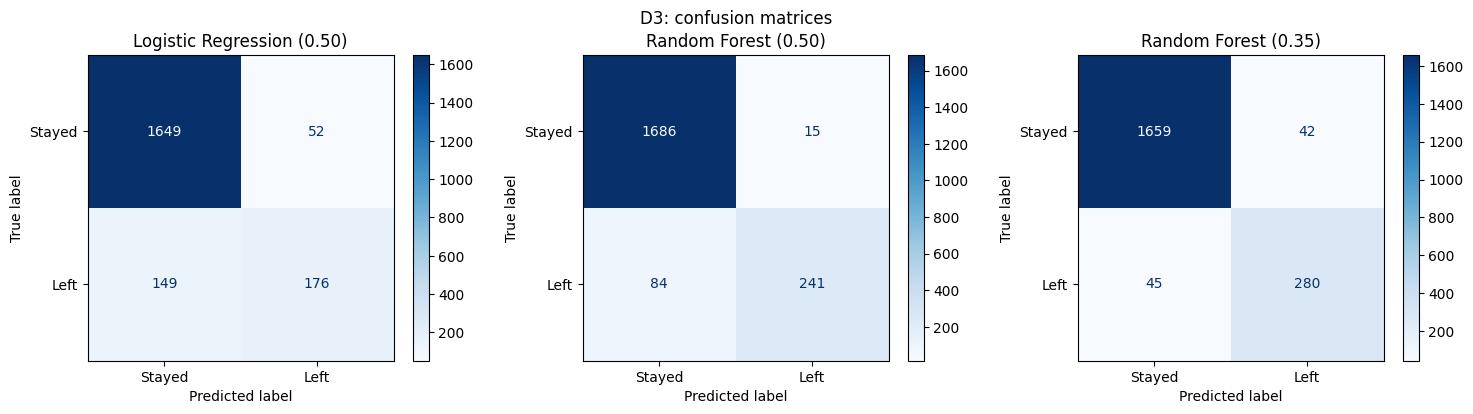

ROC-AUC  LR: 0.9166 | RF: 0.9853


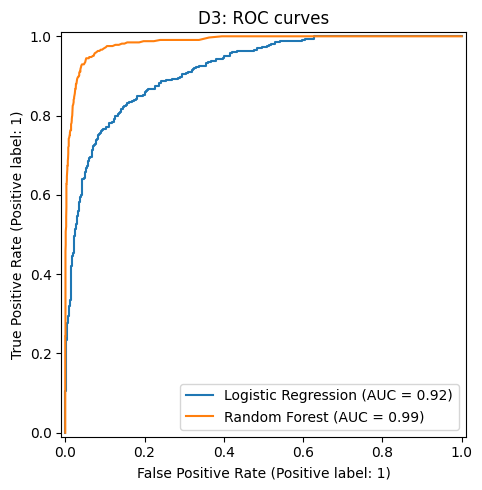

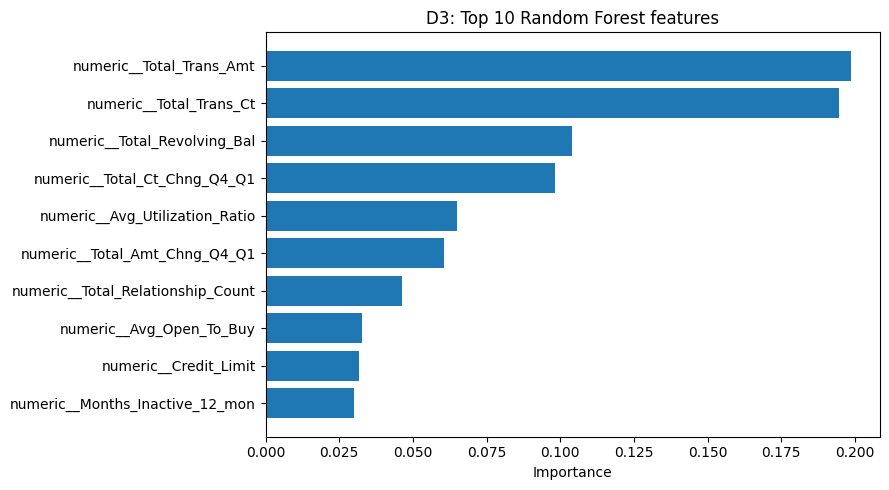

,Dataset,Model,Accuracy,Churn precision,Churn recall,Churn F1-score,ROC-AUC,Churn rate %,Rows
0,D3,Logistic Regression (0.50),0.9008,0.7719,0.5415,0.6365,0.9166,16.07,10127
1,D3,Random Forest (0.50),0.9511,0.9414,0.7415,0.8296,0.9853,16.07,10127
2,D3,Random Forest (0.35),0.9571,0.8696,0.8615,0.8655,0.9853,16.07,10127


In [ ]:
ALL["D3"] = run_pipeline("D3")

## 8. Cross-dataset comparison

One row per dataset and model. Compare **churn recall, F1 and ROC-AUC**, not accuracy alone, because all three datasets are imbalanced (the churn class is the minority).

,Dataset,Model,Accuracy,Churn precision,Churn recall,Churn F1-score,ROC-AUC,Churn rate %,Rows
0,D1,Logistic Regression (0.50),0.8080,0.5891,0.1867,0.2836,0.7748,20.37,10000
1,D1,Random Forest (0.50),0.8615,0.7876,0.4373,0.5624,0.8553,20.37,10000
2,D1,Random Forest (0.35),0.8520,0.6512,0.5872,0.6176,0.8553,20.37,10000
3,D2,Logistic Regression (0.50),0.8335,0.6937,0.3813,0.4921,0.8145,21.16,165034
4,D2,Random Forest (0.50),0.8596,0.7375,0.5226,0.6117,0.8739,21.16,165034
5,D2,Random Forest (0.35),0.8477,0.6375,0.6493,0.6434,0.8739,21.16,165034
6,D3,Logistic Regression (0.50),0.9008,0.7719,0.5415,0.6365,0.9166,16.07,10127
7,D3,Random Forest (0.50),0.9511,0.9414,0.7415,0.8296,0.9853,16.07,10127
8,D3,Random Forest (0.35),0.9571,0.8696,0.8615,0.8655,0.9853,16.07,10127


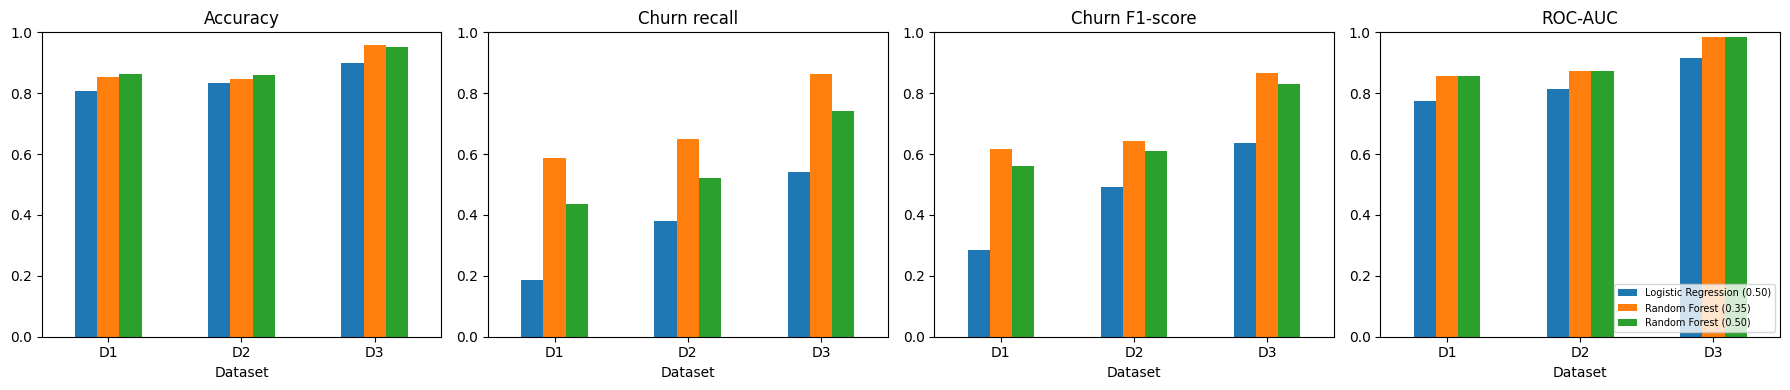

Saved cross_dataset_results.csv


In [ ]:
final = pd.concat([ALL[k]["results"] for k in ALL], ignore_index=True)
display(final.round(4))

metrics = ["Accuracy", "Churn recall", "Churn F1-score", "ROC-AUC"]
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4))
for ax, m in zip(axes, metrics):
    final.pivot(index="Dataset", columns="Model", values=m).plot(kind="bar", ax=ax, rot=0, legend=False)
    ax.set_title(m); ax.set_ylim(0, 1)
axes[-1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

final.round(4).to_csv("cross_dataset_results.csv", index=False)
print("Saved cross_dataset_results.csv")

## 9. Optional: save the Random Forest pipelines

Off by default because the D2 forest can be large. Set `SAVE_MODELS = True` in Section 1 (or run the cell below after changing it) to write one `.joblib` per dataset. Only load joblib files you trust.

In [ ]:
import joblib
SAVE_MODELS = True  # change to True to save
if SAVE_MODELS:
    for k, r in ALL.items():
        joblib.dump(r["rf_model"], f"random_forest_{k}.joblib")
        joblib.dump(r["columns"], f"input_features_{k}.joblib")
        print("Saved model for", k)
else:
    print("SAVE_MODELS is False; nothing saved.")

Saved model for D1
Saved model for D2
Saved model for D3


## 10. Discussion and limitations

Write your conclusions **from the tables printed above**; do not copy numbers from anywhere else.

Points to address:
1. Compare Logistic Regression and Random Forest on churn recall, F1 and ROC-AUC for each dataset.
2. Explain how the 0.35 threshold changes recall versus precision.
3. Do the top features agree across D1 and D2 (similar schemas)? D3 has different features, so compare only at a conceptual level.
4. Explain why accuracy is misleading when only ~16–20% of customers churn.

**Limitations**
1. One train/test split per dataset; no cross-validation or hyper-parameter tuning.
2. Associations are not causes.
3. D2 is a competition dataset generated from a real bank dataset and may not behave like real customers.
4. D3 is credit-card customers, a different population from D1/D2.
5. The 0.35 threshold is illustrative; a production threshold needs validation data and business costs.
6. Fairness and privacy (Geography, Gender, Age) need review before any real use.

## References
1. Kaggle, Churn Modelling: https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling
2. Kaggle, Playground Series S4E1: https://www.kaggle.com/competitions/playground-series-s4e1
3. Kaggle, Credit Card Customers: https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers
4. scikit-learn: https://scikit-learn.org/stable/